# Model Selection

**Benchamarked Models (regression problem)**

- Explainable Boosting (GAM ensemble boosting)
https://interpret.ml/docs/python/api/ExplainableBoostingRegressor.html

- Random Forest (ensemble bagging)
https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html

- Super Vector (kernel)
https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVR.html#sklearn.svm.SVR

- Elastic Net (regularized linear)
https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNet.html#sklearn.linear_model.ElasticNet

- Deep Learning (neural networks)
https://docs.fast.ai/


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import itertools
import os
import time

In [ ]:
# Reegression models
from sklearn.ensemble import RandomForestRegressor
from xgboost.sklearn import XGBRegressor
from sklearn.svm import SVR
from sklearn.linear_model import ElasticNet
from interpret.glassbox import ExplainableBoostingRegressor
from sklearn.metrics import mean_squared_error

In [12]:
sns.set_theme(style="darkgrid")
sns.set_palette('tab10')

In [13]:
seed=112358

In [14]:
df_projects=pd.read_csv(os.path.join('results','model_selection_projects.csv'))
df_selection=df_projects[df_projects['ModelSelection']==True]
df_selection[['Project','SP']].groupby('SP').count()

,Project
SP,
0.068966,10
0.172414,10
0.275862,10
0.379310,10
0.482759,10
0.586207,10
0.689655,10
0.793103,10
0.896552,10


## Some model testing

### Random Forest

In [1]:
from sklearn.ensemble import RandomForestRegressor

In [ ]:
# Hyperparameters of Random Forest
hyperparam={"n_estimators": [100,500,1000],
            "max_depth": [1,5,10]}

In [ ]:
mdl_name="rfr"
mse_test = []
for sp in df_selection['SP'].unique():

    print(f"Runing SP: {sp}...")

    # List of projects for training and testing
    for project in df_selection.loc[df_selection['SP'] == sp,'Project']:
        df = pd.read_csv(os.path.join('results',f"{project}_simulation_e1.csv"),index_col=0)

        # Read test runs
        df_runs= pd.read_csv(os.path.join('results',"test_runs.csv"))

        # Training data
        df_train=df.loc[df.index.difference(df_runs['test_runs'].values)]
        Xtrain=df_train.iloc[:,:32]
        Ytrain=df_train.iloc[:,-1]
        
        # Testing data
        df_test=df.loc[df_runs['test_runs'].values]
        Xtest=df_test.iloc[:,:32]
        Ytest=df_test.iloc[:,-1]

        # Test all combinations of hiperparameters
        for combination in itertools.product(hyperparam['n_estimators'], hyperparam['max_depth']):
            # Train the model
            model = RandomForestRegressor(n_estimators=combination[0], max_depth=combination[1],n_jobs=-1,random_state=seed)
            model.fit(Xtrain,Ytrain)
            # Predict the test set
            Ypred=model.predict(Xtest)
            # Calculate the MSE
            mse = mean_squared_error(Ytest, Ypred)
            # Update the test runs
            mse_test.append([sp,project,combination[0],combination[1],mse])
# Save the results of the model selection
pd.DataFrame(mse_test,columns=['SP','Project','n_estimators','max_depth','MSE']).to_csv(os.path.join('results',f"model_selection_{mdl_name}.csv"),index=False)


Runing SP: 0.1724137931034483...
Runing SP: 0.0689655172413793...
Runing SP: 0.2758620689655172...
Runing SP: 0.3793103448275862...
Runing SP: 0.4827586206896552...
Runing SP: 0.5862068965517241...
Runing SP: 0.6896551724137931...
Runing SP: 0.7931034482758621...
Runing SP: 0.896551724137931...


In [6]:
df_rf=pd.read_csv(os.path.join('results',f"model_selection_rfr.csv"))

In [7]:
results=df_rf.groupby(['SP','n_estimators','max_depth']).agg({'MSE':'mean'}).reset_index()
for sp in results['SP'].unique():
    df_sp=results[results['SP']==sp].sort_values(by='MSE')
    print(f"SP: {sp} - Best hiperparameters: n_estimators={df_sp.iloc[0,1]} and max_depth={df_sp.iloc[0,2]}")

SP: 0.0689655172413793 - Best hiperparameters: n_estimators=1000 and max_depth=10
SP: 0.1724137931034483 - Best hiperparameters: n_estimators=1000 and max_depth=10
SP: 0.2758620689655172 - Best hiperparameters: n_estimators=1000 and max_depth=10
SP: 0.3793103448275862 - Best hiperparameters: n_estimators=1000 and max_depth=10
SP: 0.4827586206896552 - Best hiperparameters: n_estimators=500 and max_depth=10
SP: 0.5862068965517241 - Best hiperparameters: n_estimators=1000 and max_depth=10
SP: 0.6896551724137931 - Best hiperparameters: n_estimators=1000 and max_depth=10
SP: 0.7931034482758621 - Best hiperparameters: n_estimators=1000 and max_depth=10
SP: 0.896551724137931 - Best hiperparameters: n_estimators=1000 and max_depth=10


### FastAI tabular

In [15]:
from fastai.tabular.all import *
from fastai.metrics import mse
from sklearn.model_selection import train_test_split

In [16]:
# (0) Load the dataset
sp=0.0689655172413793
project='ev10'

df = pd.read_csv(os.path.join('results',f"{project}_simulation_e1.csv"),index_col=0)
df_runs= pd.read_csv(os.path.join('results',"test_runs.csv"))

# Training data
df_train=df.loc[df.index.difference(df_runs['test_runs'].values)]
# Testing data
df_test=df.loc[df_runs['test_runs'].values]


In [18]:
# (1) Prepare training/validation set
splits = RandomSplitter(valid_pct=0.1)(range_of(df_train)) # We assign the validation set to 10% of the training data
to = TabularPandas(df_train, 
        procs=[Categorify, FillMissing,Normalize],
        cat_names = [],
        cont_names = [ col for col in df_train.columns if col.startswith('duration')],
        y_names='actual_duration',
        splits=splits)
# Create DataLoaders, 'dls' will have 'train' and 'valid' DataLoaders
dls = to.dataloaders(bs=64) # Try other batch sizes?

# (2) Ste the hypermarameters to try (layers of the neural network)
layer_configs = [ [100, 50],[200, 100]]

# (3) Train the model with different architectures
epochs = 100
results = {} # Dictionary to store results for different architectures
for i, layers in enumerate(layer_configs):
    print(f"\nTraining model with layers: {layers}")
    learn = tabular_learner(
        dls,
        layers=layers,
        metrics=mse,
        loss_func=MSELossFlat(), # Mean Squared Error as regression loss
        cbs=[EarlyStoppingCallback(monitor='valid_loss', patience=10)]
    )
    # Train the model
    lr_suggestion = learn.lr_find(show_plot=False);
    learn.fit_one_cycle(epochs, lr_max=lr_suggestion);
    val_loss, *val_metrics = learn.validate()
    results[str(layers)] = {'val_loss': val_loss, 'val_mse': val_metrics[0], 'model': learn.model.state_dict()}

# (4) Find the best model based on validation MSE
best_layers = None
best_mse = float('inf')
best_model_state = None

for layers_str, metrics in results.items():
    if metrics['val_mse'] < best_mse:
        best_mse = metrics['val_mse']
        best_layers = layers_str
        best_model_state = metrics['model']
print(f"\nBest model architecture: {best_layers} with validation MSE: {best_mse}")

# (5) Test the best model on the test dataset
# Load the best model's state dictionary
best_learn = tabular_learner(
    dls,
    layers=eval(best_layers), # Convert the string back to a list
    metrics=mse,
    loss_func=MSELossFlat()
)
best_learn.model.load_state_dict(best_model_state)

# Evaluate the best model on the test dataset
test_dl = best_learn.dls.test_dl(df_test)
test_preds = best_learn.get_preds(dl=test_dl)
test_mse = mse(test_preds[0], tensor(df_test['actual_duration'].values)).item()
print(f"\nTest MSE of the best model: {test_mse}")



Training model with layers: [100, 50]


epoch,train_loss,valid_loss,mse,time
0,447.657593,442.914093,442.914093,00:01
1,429.430115,418.858643,418.858643,00:01
2,384.777954,358.657471,358.657471,00:01
3,303.643951,258.058289,258.058289,00:01
4,180.951660,120.445465,120.445465,00:01
5,58.153255,16.161863,16.161863,00:01
6,7.762363,0.399730,0.399730,00:01
7,1.100514,0.271993,0.271993,00:01
8,0.280067,0.132486,0.132486,00:01
9,0.158235,0.107746,0.107746,00:01


No improvement since epoch 40: early stopping



Training model with layers: [200, 100]


epoch,train_loss,valid_loss,mse,time
0,442.828125,434.967346,434.967346,00:01
1,407.679810,384.498749,384.498749,00:01
2,330.853241,284.971039,284.971039,00:01
3,201.758575,138.100876,138.100876,00:01
4,63.911652,16.221489,16.221489,00:01
5,8.760082,1.312502,1.312502,00:01
6,1.770286,0.869670,0.869670,00:01
7,0.793669,0.701408,0.701408,00:01
8,0.581588,0.408423,0.408423,00:01
9,0.431904,0.299194,0.299194,00:01


No improvement since epoch 14: early stopping



Best model architecture: [100, 50] with validation MSE: 0.007887988351285458



Test MSE of the best model: 0.008088593371212482


## Show model selection results (from Altamira)

In [111]:
models = [(m,f"model_selection_{m}.csv") for m in ['rf','xgb','sv','en','ebm','fastai'] ]
df_selection=pd.DataFrame(columns=['Model','SP','Project','Param','MSE'])
for m,file in models:
    if os.path.exists(os.path.join('results',file)):
        df = pd.read_csv(os.path.join('results',file))
        df['Param']=df.iloc[:,2].astype(str)+"/"+df.iloc[:,3].astype(str)
        df['Model']=m
        df_selection=pd.concat([df_selection,df[['Model','SP','Project','Param','MSE']]],ignore_index=True)
    else:
        print(f"File {file} not found")

File model_selection_ebm.csv not found
File model_selection_fastai.csv not found


C:\Users\jisma\AppData\Local\Temp\ipykernel_12316\1326219258.py:8: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_selection=pd.concat([df_selection,df[['Model','SP','Project','Param','MSE']]],ignore_index=True)


### Random Forest

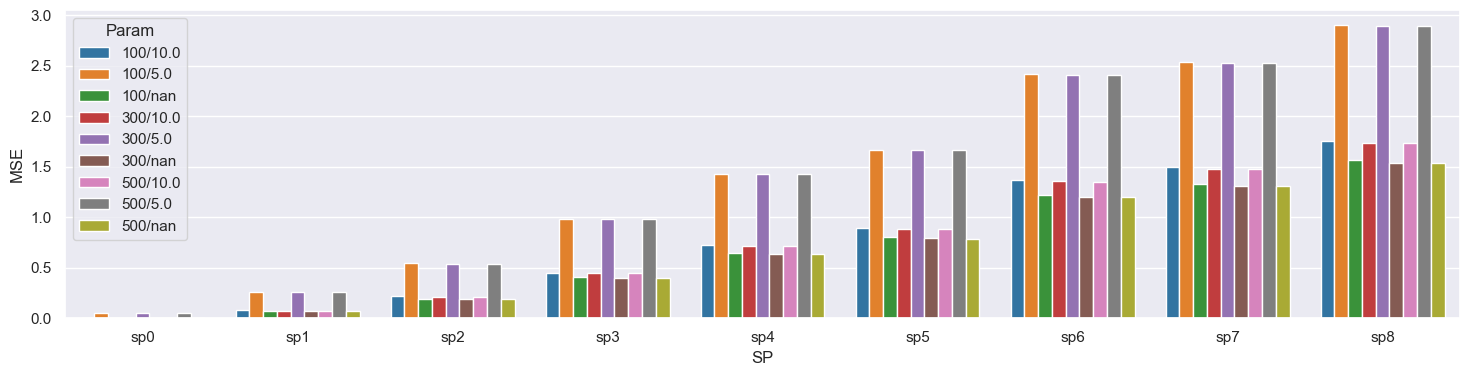

In [65]:
# Random Forest
df_model=df_selection[df_selection['Model']=='rf']
df_agg=df_model[['SP','Param','MSE']].groupby(['SP','Param']).agg({'MSE':'mean'}).reset_index()
plt.figure(figsize=(18,4))
sns.barplot(data=df_agg,x='SP',y='MSE',hue='Param')
plt.xticks(np.arange(9),['sp'+str(i) for i in range(9)]);

In [84]:
# Show the best hyperparameters (minimum MSE) for each SP
df_lowest_mse_rf = df_agg.loc[df_agg.groupby('SP')['MSE'].idxmin()]
df_lowest_mse_rf

,SP,Param,MSE
7,0.068966,500/0.1,0.003373
16,0.172414,500/0.1,0.019587
25,0.275862,500/0.1,0.042480
34,0.379310,500/0.1,0.089299
43,0.482759,500/0.1,0.149113
52,0.586207,500/0.1,0.193516
61,0.689655,500/0.1,0.320264
70,0.793103,500/0.1,0.358266
79,0.896552,500/0.1,0.446011


### XGBoost

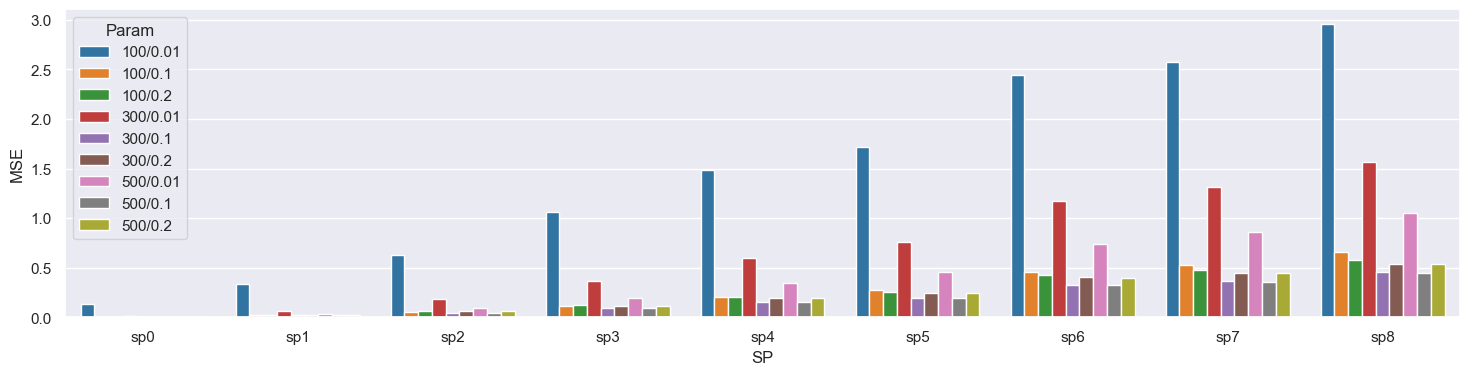

In [83]:
# XGBoost
df_model=df_selection[df_selection['Model']=='xgb']
df_agg=df_model[['SP','Param','MSE']].groupby(['SP','Param']).agg({'MSE':'mean'}).reset_index()
plt.figure(figsize=(18,4))
sns.barplot(data=df_agg,x='SP',y='MSE',hue='Param')
plt.xticks(np.arange(9),['sp'+str(i) for i in range(9)]);

In [85]:
# Show the best hyperparameters (minimum MSE) for each SP
df_lowest_mse_xg = df_agg.loc[df_agg.groupby('SP')['MSE'].idxmin()]
df_lowest_mse_xg

,SP,Param,MSE
7,0.068966,500/0.1,0.003373
16,0.172414,500/0.1,0.019587
25,0.275862,500/0.1,0.042480
34,0.379310,500/0.1,0.089299
43,0.482759,500/0.1,0.149113
52,0.586207,500/0.1,0.193516
61,0.689655,500/0.1,0.320264
70,0.793103,500/0.1,0.358266
79,0.896552,500/0.1,0.446011


### Super Vector

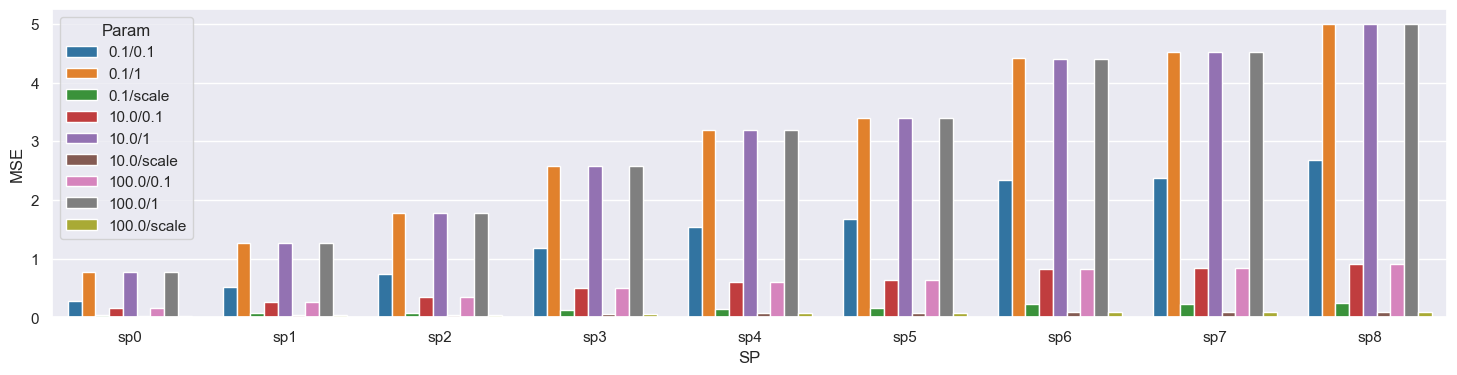

In [86]:
# Super Vector
df_model=df_selection[df_selection['Model']=='sv']
df_agg=df_model[['SP','Param','MSE']].groupby(['SP','Param']).agg({'MSE':'mean'}).reset_index() 
plt.figure(figsize=(18,4))
sns.barplot(data=df_agg,x='SP',y='MSE',hue='Param')
plt.xticks(np.arange(9),['sp'+str(i) for i in range(9)]);

In [88]:
# Show the best hyperparameters (minimum MSE) for each SP
df_lowest_mse_sv = df_agg.loc[df_agg.groupby('SP')['MSE'].idxmin()]
df_lowest_mse_sv

,SP,Param,MSE
5,0.068966,10.0/scale,0.025072
14,0.172414,10.0/scale,0.037291
23,0.275862,10.0/scale,0.041616
35,0.379310,100.0/scale,0.057677
44,0.482759,100.0/scale,0.064365
53,0.586207,100.0/scale,0.069331
62,0.689655,100.0/scale,0.086056
71,0.793103,100.0/scale,0.086272
80,0.896552,100.0/scale,0.090834


In [96]:
for sp in df_agg['SP'].unique()[:3]: # Compare the tree SPs for the two best models
    for p in ['10.0/scale','100.0/scale']:
        print(f"SP: {sp}, Param: {p}, MSE: {df_agg.loc[(df_agg['SP']==sp) & (df_agg['Param']==p),'MSE'].values[0]:0.6f}")


SP: 0.0689655172413793, Param: 10.0/scale, MSE: 0.025072
SP: 0.0689655172413793, Param: 100.0/scale, MSE: 0.025072
SP: 0.1724137931034483, Param: 10.0/scale, MSE: 0.037291
SP: 0.1724137931034483, Param: 100.0/scale, MSE: 0.037295
SP: 0.2758620689655172, Param: 10.0/scale, MSE: 0.041616
SP: 0.2758620689655172, Param: 100.0/scale, MSE: 0.041619


### Elastic Net

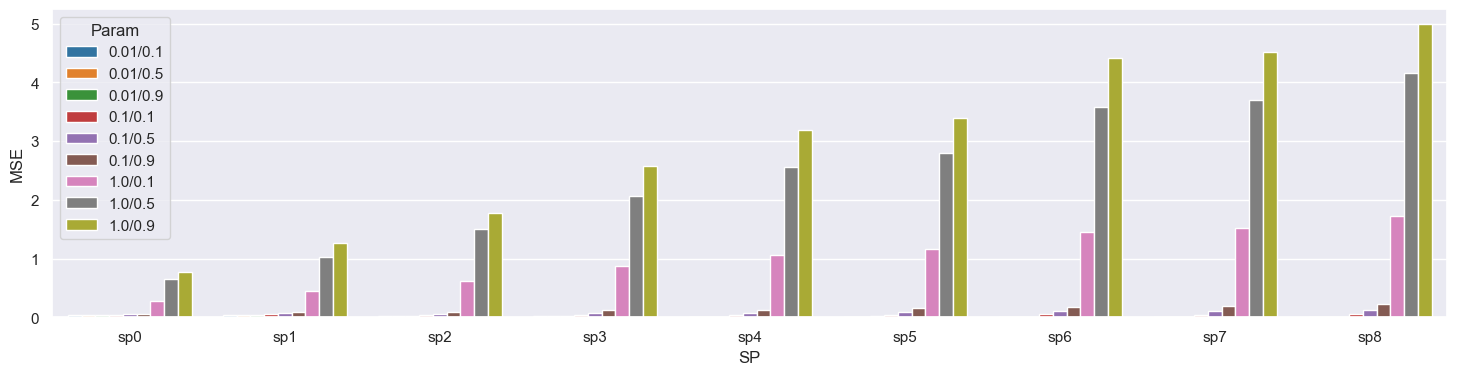

In [97]:
### Elastic Net
df_model=df_selection[df_selection['Model']=='en']  
df_agg=df_model[['SP','Param','MSE']].groupby(['SP','Param']).agg({'MSE':'mean'}).reset_index()
plt.figure(figsize=(18,4))
sns.barplot(data=df_agg,x='SP',y='MSE',hue='Param')
plt.xticks(np.arange(9),['sp'+str(i) for i in range(9)]);

In [98]:
# Show the best hyperparameters (minimum MSE) for each SP
df_lowest_mse_en = df_agg.loc[df_agg.groupby('SP')['MSE'].idxmin()]
df_lowest_mse_en

,SP,Param,MSE
0,0.068966,0.01/0.1,0.034502
9,0.172414,0.01/0.1,0.044604
18,0.275862,0.01/0.1,0.021379
27,0.379310,0.01/0.1,0.020604
36,0.482759,0.01/0.1,0.002167
45,0.586207,0.01/0.1,0.012127
54,0.689655,0.01/0.1,0.009866
63,0.793103,0.01/0.1,0.000544
72,0.896552,0.01/0.1,0.000617


In [112]:
# Model benchmarking
df_benchmarking=pd.DataFrame(df_lowest_mse_rf['MSE'].values,columns=['RF'])
df_benchmarking=pd.concat([df_benchmarking,pd.DataFrame(df_lowest_mse_xg['MSE'].values,columns=['XGB'])],axis=1)
df_benchmarking=pd.concat([df_benchmarking,pd.DataFrame(df_lowest_mse_sv['MSE'].values,columns=['SV'])],axis=1)
df_benchmarking=pd.concat([df_benchmarking,pd.DataFrame(df_lowest_mse_en['MSE'].values,columns=['EN'])],axis=1)
df_benchmarking


,RF,XGB,SV,EN
0,0.003373,0.003373,0.025072,0.034502
1,0.019587,0.019587,0.037291,0.044604
2,0.042480,0.042480,0.041616,0.021379
3,0.089299,0.089299,0.057677,0.020604
4,0.149113,0.149113,0.064365,0.002167
5,0.193516,0.193516,0.069331,0.012127
6,0.320264,0.320264,0.086056,0.009866
7,0.358266,0.358266,0.086272,0.000544
8,0.446011,0.446011,0.090834,0.000617


<Axes: >

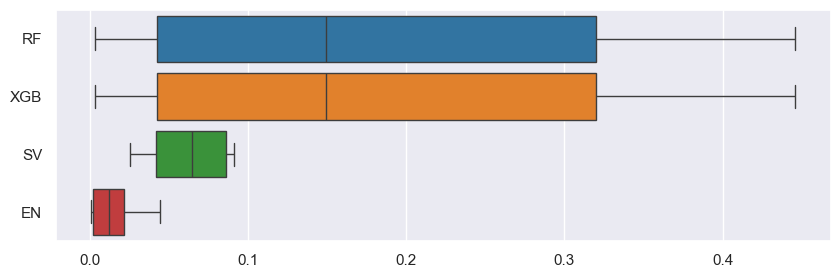

In [113]:
plt.figure(figsize=(10,3))
sns.boxplot(data=df_benchmarking,orient='h')